In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('data/zestaw_nr_1_11_16.csv')


df.loc[df['freq_y']>150]=0
df.loc[df['freq_z']>150]=0
df.loc[df['freq_x']>150]=0

print(df.head())


   frame   fs  clip_x  clip_y  clip_z  freq_x  freq_y  freq_z  amp_x  amp_y  \
0     21  800       0       0       0   18.27    9.93    4.03  0.149  0.072   
1     21  800       0       0       0   12.91   18.27     NaN  0.122  0.066   
2     21  800       0       0       0   19.94   12.90     NaN  0.114  0.060   
3     21  800       0       0       0    9.97   20.07     NaN  0.110  0.059   
4     21  800       0       0       0    3.25   22.48     NaN  0.106  0.056   

   amp_z  
0  0.057  
1    NaN  
2    NaN  
3    NaN  
4    NaN  


centroid osi x: 17.05Hz
centroid osi y: 15.39Hz
centroid osi z: 16.92Hz


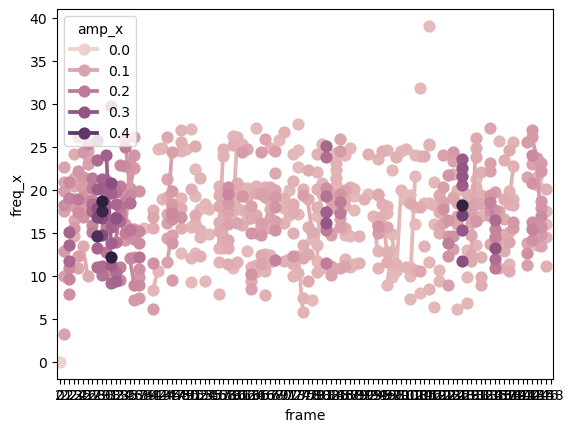

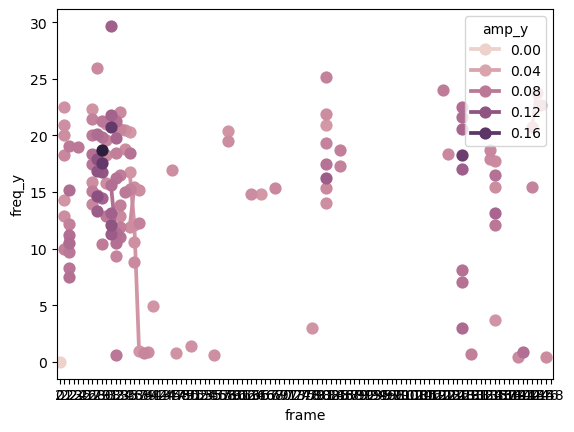

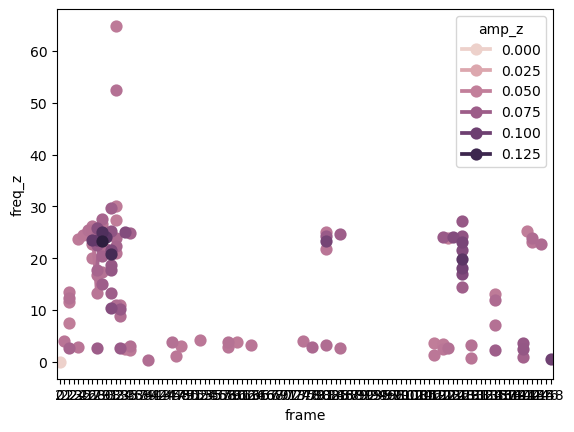

In [17]:
f,ax=plt.subplots()
ax=sns.pointplot(data=df,x='frame',y='freq_x',hue='amp_x',errorbar=None)

f,ax=plt.subplots()
ax=sns.pointplot(data=df,x='frame',y='freq_y',hue='amp_y',errorbar=None)

f,ax=plt.subplots()
ax=sns.pointplot(data=df,x='frame',y='freq_z',hue='amp_z',errorbar=None)

freqx=df['freq_x'].fillna(0)
freqy=df['freq_y'].fillna(0)
freqz=df['freq_z'].fillna(0)

ampx=df['amp_x'].fillna(0)
ampy=df['amp_y'].fillna(0)
ampz=df['amp_z'].fillna(0)




suma_licz=0
suma_mian=0

for i in freqx.index:
    suma_licz+=(freqx.values)[i]*(ampx.values)[i]*(ampx.values)[i]
    suma_mian+=(ampx.values)[i]*(ampx.values)[i]

centroid_x=suma_licz/suma_mian

suma_licz=0
suma_mian=0

for i in freqy.index:
    suma_licz+=(freqy.values)[i]*(ampy.values)[i]*(ampy.values)[i]
    suma_mian+=(ampy.values)[i]*(ampy.values)[i]

centroid_y=suma_licz/suma_mian

suma_licz=0
suma_mian=0

for i in freqz.index:
    suma_licz+=(freqz.values)[i]*(ampz.values)[i]*(ampz.values)[i]
    suma_mian+=(ampz.values)[i]*(ampz.values)[i]

centroid_z=suma_licz/suma_mian

print(f'centroid osi x: {centroid_x:.2f}Hz')
print(f'centroid osi y: {centroid_y:.2f}Hz')
print(f'centroid osi z: {centroid_z:.2f}Hz')


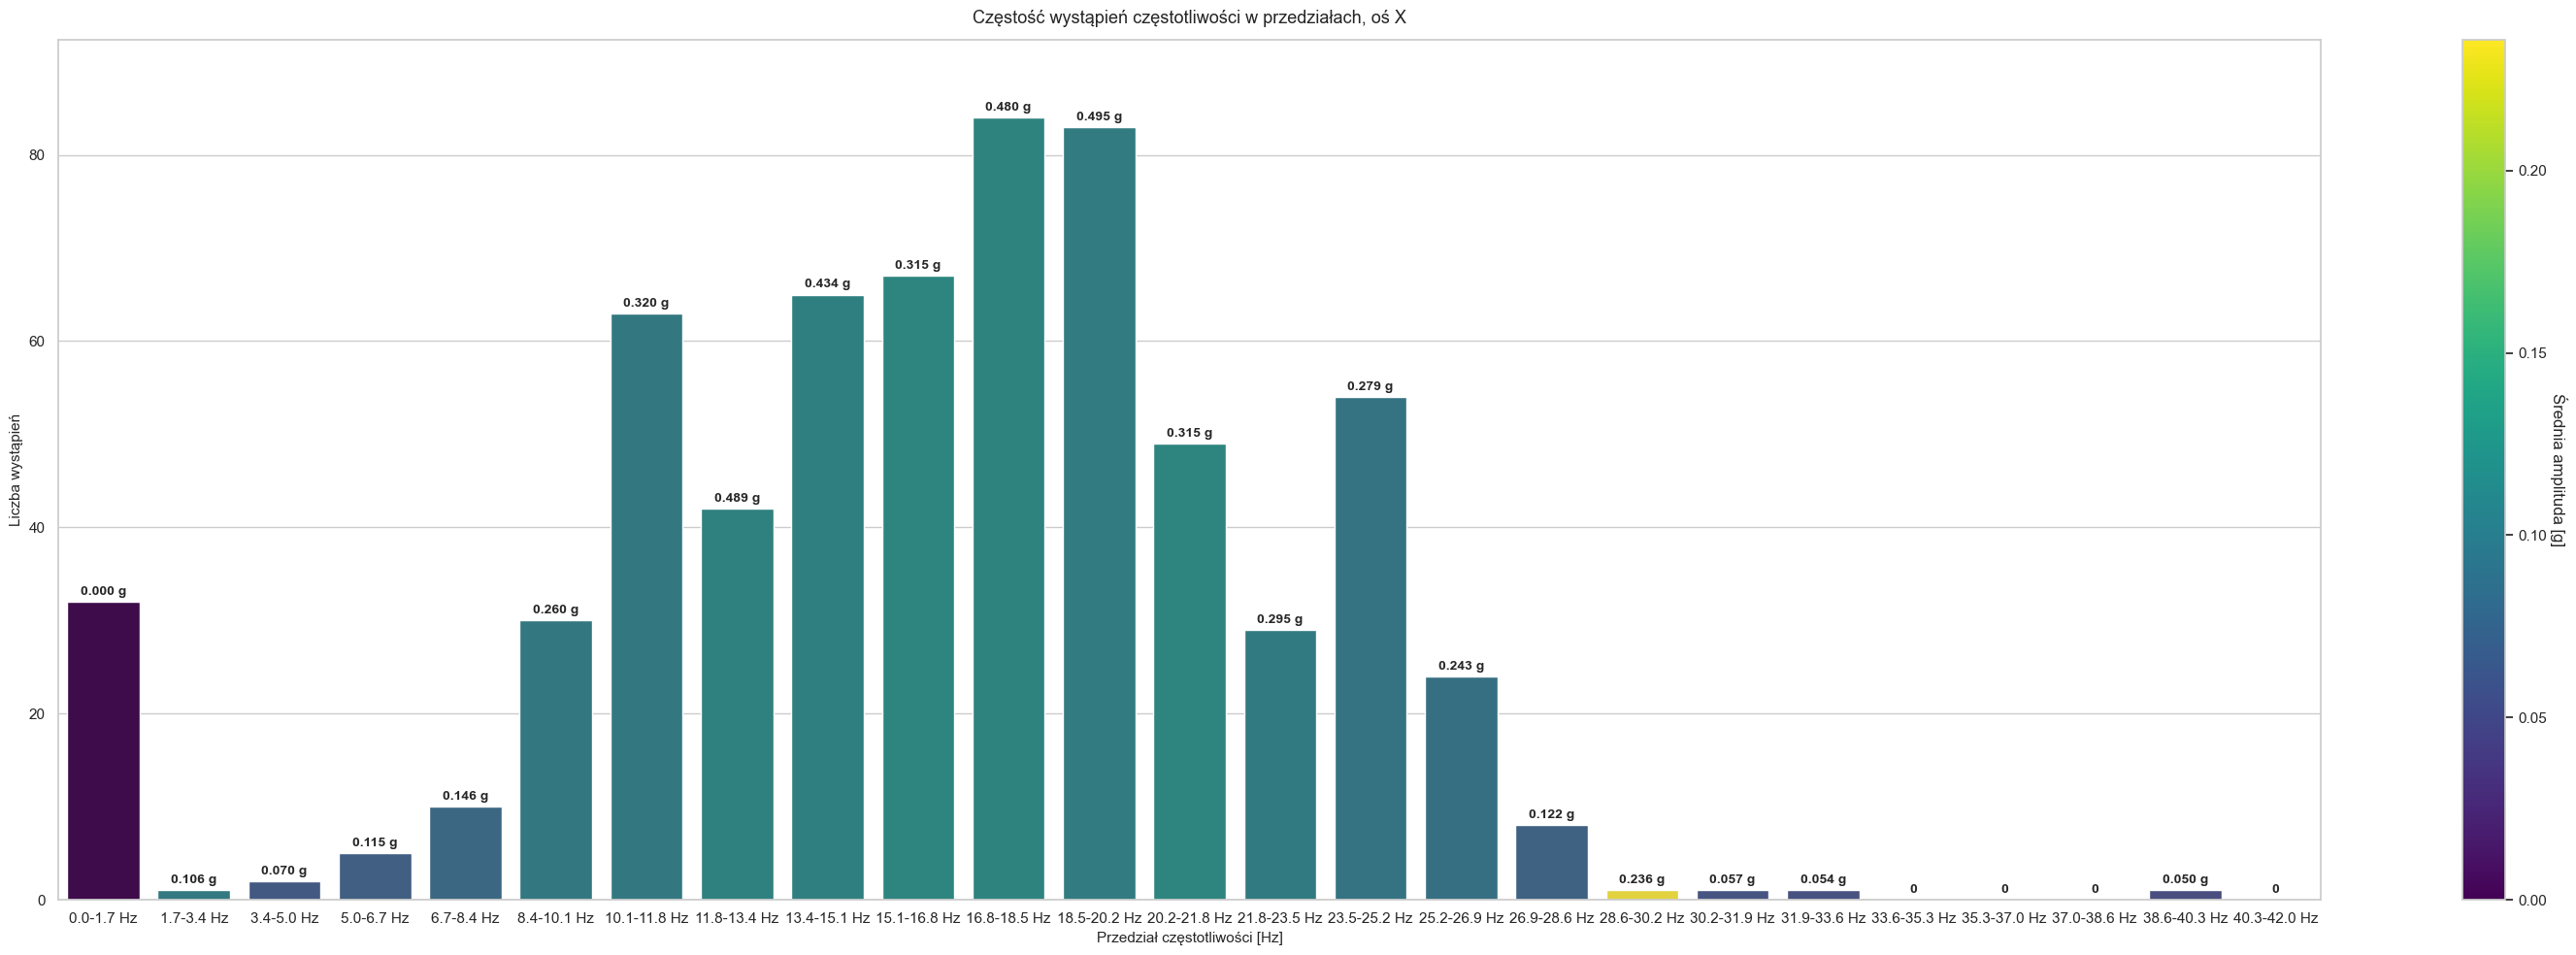

In [8]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors



#1. Przekształcenie danych ze wszystkich osi (X, Y, Z) do wspólnych kolumn
'''df_long = pd.concat([
    df[['freq_x', 'amp_x']].rename(columns={'freq_x': 'freq', 'amp_x': 'amp'}).assign(axis='X'),
    df[['freq_y', 'amp_y']].rename(columns={'freq_y': 'freq', 'amp_y': 'amp'}).assign(axis='Y'),
    df[['freq_z', 'amp_z']].rename(columns={'freq_z': 'freq', 'amp_z': 'amp'}).assign(axis='Z')
]).dropna()'''

df_long = df[['freq_x', 'amp_x']].rename(columns={'freq_x': 'freq', 'amp_x': 'amp'}).dropna()

# 2. Podział częstotliwości na przedziały (koszyki)

bins=[]
labels=[]

ilosc_przedzialow=25
maks_freq=42

krok=maks_freq/ilosc_przedzialow

for i in range(ilosc_przedzialow):
    bins.append(i*krok)
    labels.append(f'{i*krok:.1f}-{i*krok+krok:.1f} Hz')
    if i==ilosc_przedzialow-1:
        bins.append(ilosc_przedzialow*krok)

#print(len(bins))
#print(len(labels))

#bins = [0,2.5, 5,7.5, 10,12.5, 15,17.5, 20,22.5, 25,27.5, 30,32.5,35,37.5,40]
#labels = ['0-2.5 Hz','2.5-5 Hz','5-7.5 Hz', '7.5-10 Hz','10-12.5 Hz', '12.5-15 Hz','15-17.5 Hz', '17.5-20 Hz', '20-22.5 Hz','22.5-25 Hz', '25-27.5 Hz','27.5-30 Hz','30-32.5 Hz','32.5-35 Hz','35-37.5 Hz','37.5-40 Hz']

#print(len(bins))
#print(len(labels))

df_long['freq_bin'] = pd.cut(df_long['freq'], bins=bins, labels=labels, right=True, include_lowest=True)

# 3. Agregacja: zliczenie wystąpień oraz obliczenie średniej amplitudy dla każdego zakresu
summary = df_long.groupby('freq_bin', observed=False).agg(
    count=('freq', 'count'),
    mean_amp=('amp', 'mean'),
    max_amp=('amp','max')
).reset_index()

# Uzupełnienie NaN zerami dla przedziałów bez żadnych wystąpień
summary['mean_amp'] = summary['mean_amp'].fillna(0)
summary['max_amp'] = summary['max_amp'].fillna(0)

# 4. Przygotowanie mapy kolorów dla amplitudy

norm = mcolors.Normalize(vmin=summary['mean_amp'].min(), vmax=summary['mean_amp'].max())
cmap = cm.viridis  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(norm(val)) for val in summary['mean_amp']]

'''
maxamp=mcolors.Normalize(vmin=summary['max_amp'].min(), vmax=summary['max_amp'].max())
cmap = cm.inferno  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(maxamp(val)) for val in summary['max_amp']]
'''

# 5. Rysowanie wykresu
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(30, 10))

sns.barplot(
    data=summary,
    x='freq_bin',
    y='count',
    hue='freq_bin',
    palette=colors,
    legend=False,
    ax=ax
)

# Dodanie paska kolorów (colorbar) reprezentującego amplitudę
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
#sm = cm.ScalarMappable(cmap=cmap, norm=maxamp)

sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Średnia amplituda [g]', rotation=270, labelpad=15)

# Opisy osi i tytuł
ax.set_title('Częstość wystąpień częstotliwości w przedziałach, oś X', fontsize=13, pad=12)
ax.set_xlabel('Przedział częstotliwości [Hz]', fontsize=11)
ax.set_ylabel('Liczba wystąpień', fontsize=11)

# Opcjonalnie: dodanie dokładnych wartości liczbowych nad słupkami
'''for container in ax.containers:
    ax.bar_label(container,summary['mean_amp'],padding=3)'''

# Przygotowanie etykiet ze średnią amplitudą
amp_labels = [f"{val:.3f} g" if count > 0 else "0" for val, count in zip(summary['max_amp'], summary['count'])]

# Przypisanie jednej odpowiedniej etykiety do każdego kontenera (słupka)
for i, container in enumerate(ax.containers):
    ax.bar_label(container, labels=[amp_labels[i]], padding=3, fontsize=10, fontweight='bold')

# Zwiększenie górnego limitu osi Y o 10%
ax.set_ylim(0, summary['count'].max() * 1.1)

plt.tight_layout()
plt.show()

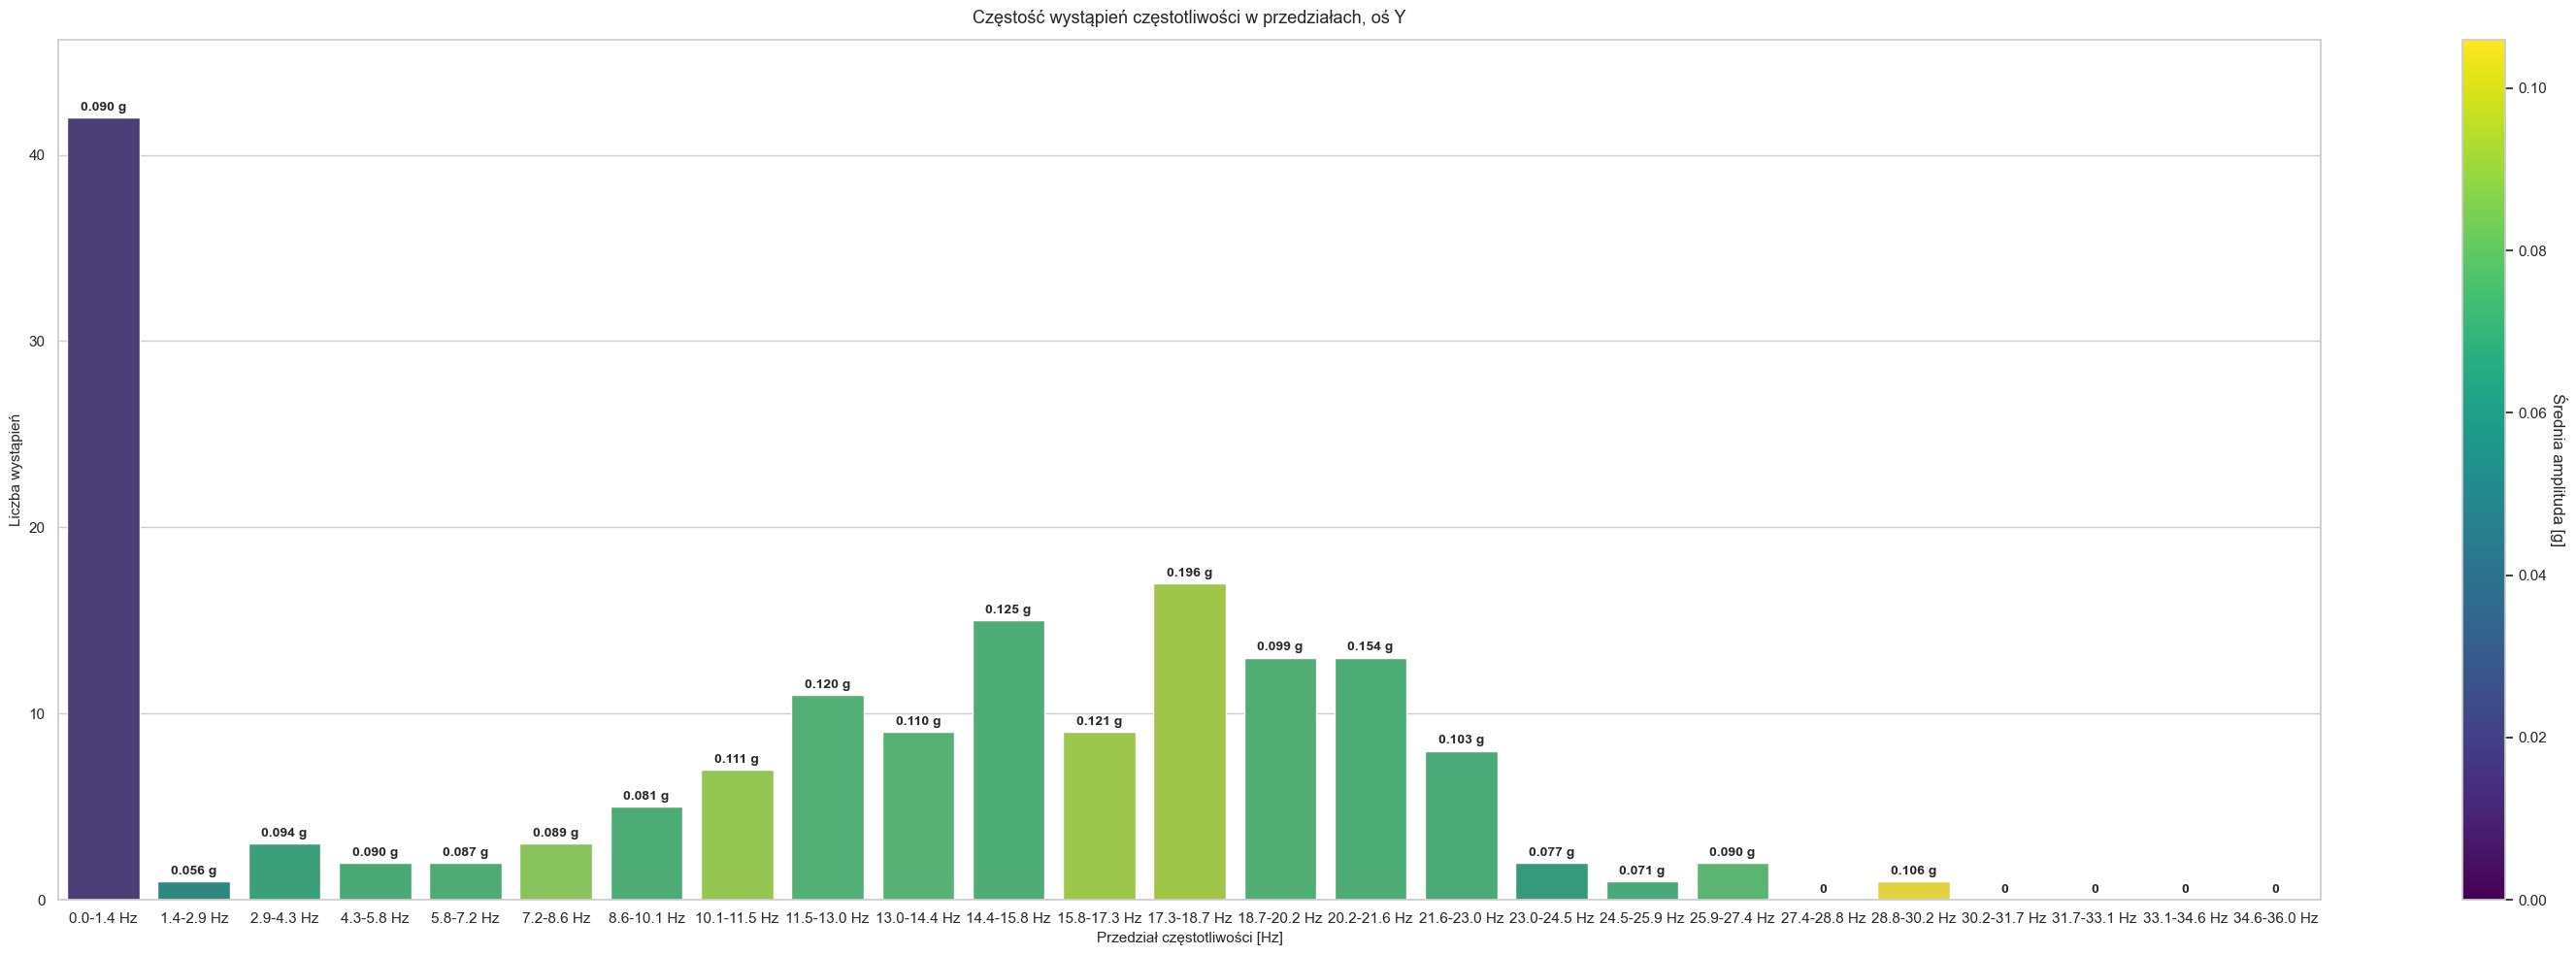

In [9]:
df_long = df[['freq_y', 'amp_y']].rename(columns={'freq_y': 'freq', 'amp_y': 'amp'}).dropna()

# 2. Podział częstotliwości na przedziały (koszyki)
bins=[]
labels=[]

ilosc_przedzialow=25
maks_freq=36

krok=maks_freq/ilosc_przedzialow

for i in range(ilosc_przedzialow):
    bins.append(i*krok)
    labels.append(f'{i*krok:.1f}-{i*krok+krok:.1f} Hz')
    if i==ilosc_przedzialow-1:
        bins.append(ilosc_przedzialow*krok)
df_long['freq_bin'] = pd.cut(df_long['freq'], bins=bins, labels=labels, right=True, include_lowest=True)

# 3. Agregacja: zliczenie wystąpień oraz obliczenie średniej amplitudy dla każdego zakresu
summary = df_long.groupby('freq_bin', observed=False).agg(
    count=('freq', 'count'),
    mean_amp=('amp', 'mean'),
    max_amp=('amp','max')
).reset_index()

# Uzupełnienie NaN zerami dla przedziałów bez żadnych wystąpień
summary['mean_amp'] = summary['mean_amp'].fillna(0)
summary['max_amp'] = summary['max_amp'].fillna(0)

# 4. Przygotowanie mapy kolorów dla amplitudy

norm = mcolors.Normalize(vmin=summary['mean_amp'].min(), vmax=summary['mean_amp'].max())
cmap = cm.viridis  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(norm(val)) for val in summary['mean_amp']]

'''
maxamp=mcolors.Normalize(vmin=summary['max_amp'].min(), vmax=summary['max_amp'].max())
cmap = cm.inferno  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(maxamp(val)) for val in summary['max_amp']]
'''

# 5. Rysowanie wykresu
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(30, 10))

sns.barplot(
    data=summary,
    x='freq_bin',
    y='count',
    hue='freq_bin',
    palette=colors,
    legend=False,
    ax=ax
)

# Dodanie paska kolorów (colorbar) reprezentującego amplitudę
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
#sm = cm.ScalarMappable(cmap=cmap, norm=maxamp)

sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Średnia amplituda [g]', rotation=270, labelpad=15)

# Opisy osi i tytuł
ax.set_title('Częstość wystąpień częstotliwości w przedziałach, oś Y', fontsize=13, pad=12)
ax.set_xlabel('Przedział częstotliwości [Hz]', fontsize=11)
ax.set_ylabel('Liczba wystąpień', fontsize=11)

# Opcjonalnie: dodanie dokładnych wartości liczbowych nad słupkami
'''for container in ax.containers:
    ax.bar_label(container,summary['mean_amp'],padding=3)'''

# Przygotowanie etykiet ze średnią amplitudą
amp_labels = [f"{val:.3f} g" if count > 0 else "0" for val, count in zip(summary['max_amp'], summary['count'])]

# Przypisanie jednej odpowiedniej etykiety do każdego kontenera (słupka)
for i, container in enumerate(ax.containers):
    ax.bar_label(container, labels=[amp_labels[i]], padding=3, fontsize=10, fontweight='bold')

# Zwiększenie górnego limitu osi Y o 10%
ax.set_ylim(0, summary['count'].max() * 1.1)

plt.tight_layout()
plt.show()

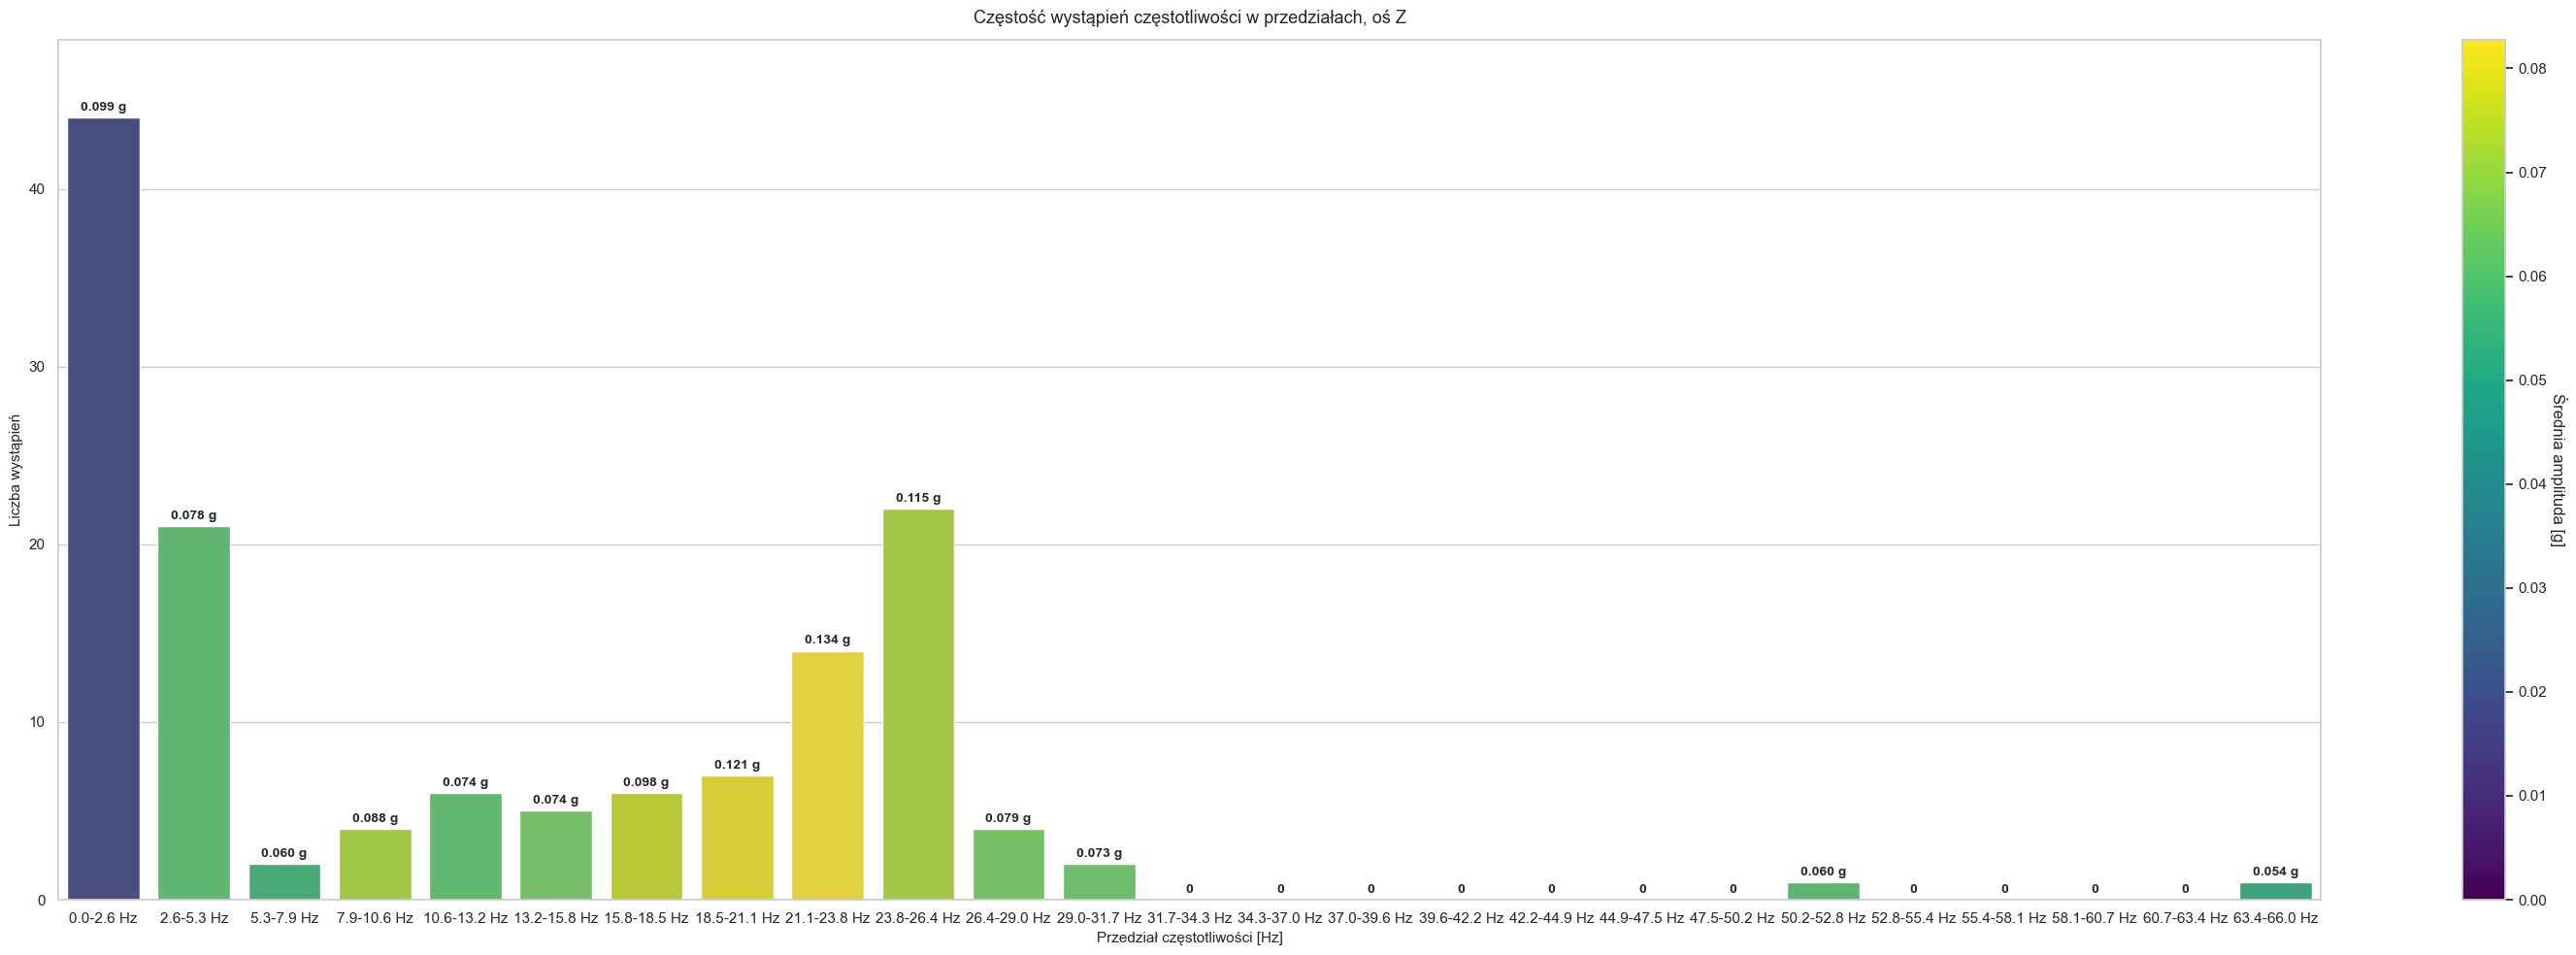

In [10]:
df_long = df[['freq_z', 'amp_z']].rename(columns={'freq_z': 'freq', 'amp_z': 'amp'}).dropna()

# 2. Podział częstotliwości na przedziały (koszyki)
bins=[]
labels=[]

ilosc_przedzialow=25
maks_freq=66

krok=maks_freq/ilosc_przedzialow

for i in range(ilosc_przedzialow):
    bins.append(i*krok)
    labels.append(f'{i*krok:.1f}-{i*krok+krok:.1f} Hz')
    if i==ilosc_przedzialow-1:
        bins.append(ilosc_przedzialow*krok)


df_long['freq_bin'] = pd.cut(df_long['freq'], bins=bins, labels=labels, right=True, include_lowest=True)

# 3. Agregacja: zliczenie wystąpień oraz obliczenie średniej amplitudy dla każdego zakresu
summary = df_long.groupby('freq_bin', observed=False).agg(
    count=('freq', 'count'),
    mean_amp=('amp', 'mean'),
    max_amp=('amp','max')
).reset_index()

# Uzupełnienie NaN zerami dla przedziałów bez żadnych wystąpień
summary['mean_amp'] = summary['mean_amp'].fillna(0)
summary['max_amp'] = summary['max_amp'].fillna(0)

# 4. Przygotowanie mapy kolorów dla amplitudy

norm = mcolors.Normalize(vmin=summary['mean_amp'].min(), vmax=summary['mean_amp'].max())
cmap = cm.viridis  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(norm(val)) for val in summary['mean_amp']]

'''
maxamp=mcolors.Normalize(vmin=summary['max_amp'].min(), vmax=summary['max_amp'].max())
cmap = cm.inferno  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(maxamp(val)) for val in summary['max_amp']]
'''

# 5. Rysowanie wykresu
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(30, 10))

sns.barplot(
    data=summary,
    x='freq_bin',
    y='count',
    hue='freq_bin',
    palette=colors,
    legend=False,
    ax=ax
)

# Dodanie paska kolorów (colorbar) reprezentującego amplitudę
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
#sm = cm.ScalarMappable(cmap=cmap, norm=maxamp)

sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Średnia amplituda [g]', rotation=270, labelpad=15)

# Opisy osi i tytuł
ax.set_title('Częstość wystąpień częstotliwości w przedziałach, oś Z', fontsize=13, pad=12)
ax.set_xlabel('Przedział częstotliwości [Hz]', fontsize=11)
ax.set_ylabel('Liczba wystąpień', fontsize=11)

# Opcjonalnie: dodanie dokładnych wartości liczbowych nad słupkami
'''for container in ax.containers:
    ax.bar_label(container,summary['mean_amp'],padding=3)'''

# Przygotowanie etykiet ze średnią amplitudą
amp_labels = [f"{val:.3f} g" if count > 0 else "0" for val, count in zip(summary['max_amp'], summary['count'])]

# Przypisanie jednej odpowiedniej etykiety do każdego kontenera (słupka)
for i, container in enumerate(ax.containers):
    ax.bar_label(container, labels=[amp_labels[i]], padding=3, fontsize=10, fontweight='bold')

# Zwiększenie górnego limitu osi Y o 10%
ax.set_ylim(0, summary['count'].max() * 1.1)

plt.tight_layout()
plt.show()